In [2]:
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda"
print(device)

cuda


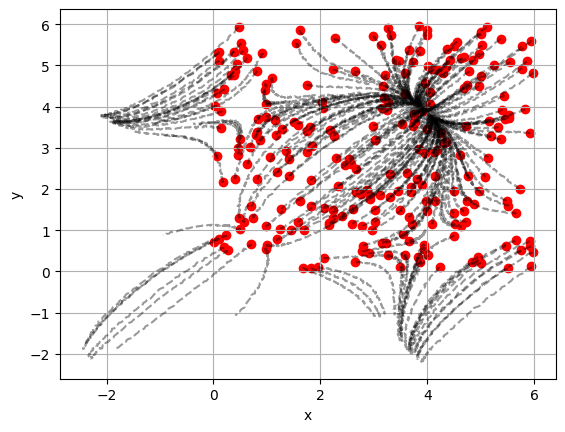

In [ ]:
class Cos(nn.Module):
   def __init__(self):
        super().__init__()

       

   def forward(self,t,z):
        x, y = z[...,0], z[...,1]
      
        dx = -2*(torch.cos(x)-torch.sin(x)) - (torch.cos(y)-torch.sin(y))
        dy = -2*(torch.cos(y)-torch.sin(y)) - (torch.cos(x) - torch.sin(x))
        return torch.stack([dx, dy], dim=-1)
   

def make_grid_dataset(T=3.0, step=60, noise_std=0.02,
                      nx=20, ny=20,
                      x_range=(0.0, 4.5), y_range=(0.0, 4.5)):
    gt = Cos().to(device)
    t = torch.linspace(0.0, T, step, device=device)

    xs = torch.linspace(x_range[0], x_range[1], nx, device=device)
    ys = torch.linspace(y_range[0], y_range[1], ny, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing='ij')

    z0 = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=-1)

    with torch.no_grad():
        z_traj = odeint(gt, z0, t, method="dopri5")
        z_traj = z_traj.transpose(0, 1).contiguous()

        if noise_std > 0:
            z_traj = z_traj + noise_std * torch.randn_like(z_traj)

    return z0, t, z_traj

def make_random_dataset(n_traj=400, T=3.0, step=60, noise_std=0.02,
                        x_range=(0.0, 6.0), y_range=(0.0, 6.0)):
    gt = Cos().to(device)
    t = torch.linspace(0.0, T, step, device=device)

    x0 = x_range[0] + (x_range[1] - x_range[0]) * torch.rand(n_traj, device=device)
    y0 = y_range[0] + (y_range[1] - y_range[0]) * torch.rand(n_traj, device=device)
    z0 = torch.stack([x0, y0], dim=-1)

    with torch.no_grad():
        z_traj = odeint(gt, z0, t, method="dopri5")
        z_traj = z_traj.transpose(0, 1).contiguous()

        if noise_std > 0:
            z_traj = z_traj + noise_std * torch.randn_like(z_traj)

    return z0, t, z_traj

z0_train, t_eval, Z_train = make_grid_dataset(
    T=1.0,
    step=100,
    noise_std=0.01,
    nx=20,
    ny=20,
    x_range=(0.0, 6.0),
    y_range=(0.0,6.0 )
)

z0_test, _, Z_test = make_random_dataset(
    n_traj=400,
    T=1.0,
    step=100,
    noise_std=0.01,
    x_range=(0.0, 6.0),
    y_range=(0.0, 6.0)
)

train_load = DataLoader(
    TensorDataset(z0_train, Z_train),
    batch_size=256,
    shuffle=True
)

test_load = DataLoader(
    TensorDataset(z0_test, Z_test),
    batch_size=256,
    shuffle=False
)

torch.save({
    "z0_train": z0_train.cpu(),
    "Z_train": Z_train.cpu(),

    "z0_test": z0_test.cpu(),
    "Z_test": Z_test.cpu(),

    "t_eval": t_eval.cpu()
}, "dataset.pt")



for z0_batch, Z_batch in test_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()

class ODEmodel(nn.Module):
    def __init__(self,state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim+(1 if time_dependent else 0)
        self.net=nn.Sequential(
            nn.Linear(in_dim, hidden),nn.Softplus(),
            nn.Linear(hidden, hidden), nn.Softplus(),
            nn.Linear(hidden,state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        

    def forward(self, t,z):
        if z.dim()==1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)
    
class NeuralODE(nn.Module):
     def __init__(self, func, use_adjoint, rtol=1e-3, atol=1e-4, method="dopri5"):
            super().__init__()
            self.func = func
            self.use_adjoint = use_adjoint
            self.rtol = rtol
            self.atol = atol
            self.method = method


     def forward(self,z0,t):
            solver= odeint_adjoint if self.use_adjoint else odeint
            Z = solver(self.func, z0, t , rtol=self.rtol, atol=self.atol, method=self.method)
            return Z.transpose(0, 1).contiguous()
def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count
    
true_equilibria = torch.tensor([
    [math.pi/4,     math.pi/4],     # unstable
    [math.pi/4,     5*math.pi/4],   # saddle
    [5*math.pi/4,   math.pi/4],     # saddle
    [5*math.pi/4,   5*math.pi/4],   # stable
], dtype=torch.float32, device=device)
def jacobian_2d(func, x, t0=0.0):
   

    x = x.clone().detach().requires_grad_(True)
    t0 = torch.tensor(float(t0), device=x.device, dtype=x.dtype)

    
    y = func(t0, x.unsqueeze(0)).squeeze(0)

    J = torch.zeros(2, 2, device=x.device, dtype=x.dtype)

    for i in range(2):
        grad = torch.autograd.grad(y[i], x, retain_graph=True)[0]
        J[i] = grad

    return J

def find_equilibrium(func, x0, t0=0.0, steps=300, lr=0.02):
    x = x0.clone().detach().to(device).requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    t0 = torch.tensor(float(t0), device=device)

    for _ in range(steps):
        v = func(t0, x.unsqueeze(0)).squeeze(0)
        loss = (v**2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        res = torch.norm(func(t0, x.unsqueeze(0)).squeeze(0)).item()
    return x.detach(), res

def analyze_equilibrium(func, epoch, t0=0.0):
    print(f"\nEpoch {epoch}")
    eq_errors = []
    eigvals_all = []

    for i, x_true_eq in enumerate(true_equilibria, 1):
        x0 = x_true_eq + 0.2 * torch.randn_like(x_true_eq)

        x_eq, res = find_equilibrium(func, x0, t0=t0, steps=300, lr=0.02)
        err = torch.norm(x_eq - x_true_eq).item()
        eq_errors.append(err)
       

        J = jacobian_2d(func, x_eq, t0=t0)
        eigvals = torch.linalg.eigvals(J)
        eigvals_all.append(eigvals.detach().cpu())

        print(f"\nEquilibrium {i}")
        print("x_equilibrium      =", x_eq.detach().cpu().numpy())
        print("x_true_equilibrium =", x_true_eq.detach().cpu().numpy())
        print("||x_eq - x_true||  =", err)
        print("residual ||f(x)||  =", res)
        print("eigenvalues        =", eigvals.detach().cpu().numpy())

    return eq_errors,eigvals_all
        
def train(model, loader, t_eval, epochs=1300, lr=1e-3, clip_grad=5.0, tag="NODE"):
    optim = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    test_losses = []
    eq_errors_history = []
    eigvals_history = []
    epoch_marks = []

    for ep in range(1, epochs + 1):
        model.train()
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred = model(z0, t_eval)
            loss = mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()
            if clip_grad:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optim.step()

        tr = evaluate(model, train_load, t_eval)
        te = evaluate(model, test_load, t_eval)

        train_losses.append(tr)
        test_losses.append(te)

        if ep % 10 == 0:
            eq_errors, eigvals_all = analyze_equilibrium(model.func, epoch=ep, t0=0.0)
            eq_errors_history.append(eq_errors)
            eigvals_history.append(eigvals_all)
            epoch_marks.append(ep)

            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")

    return model, train_losses, test_losses, eq_errors_history, eigvals_history, epoch_marks

In [58]:
func_adj = ODEmodel().to(device)
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

print("Training Neural ODE ...")
node_adj, train_losses, test_losses, eq_errors_history, eigvals_history, epoch_marks = train(
    node_adj, train_load, t_eval, tag="ADJ"
)

print("\nFinal MSE")
print("Train:", evaluate(node_adj, train_load, t_eval))
print("Test :", evaluate(node_adj, test_load,  t_eval))

torch.save({
    "model_state": node_adj.state_dict(),
    "func_state": node_adj.func.state_dict(),  
}, "node_adj.pth")

Training Neural ODE ...

Epoch 10

Equilibrium 1
x_equilibrium      = [3.8825402 4.514604 ]
x_true_equilibrium = [0.7853982 0.7853982]
||x_eq - x_true||  = 4.847603797912598
residual ||f(x)||  = 0.07888838648796082
eigenvalues        = [-0.16363418+0.j -0.05108793+0.j]

Equilibrium 2
x_equilibrium      = [4.0011024 5.054222 ]
x_true_equilibrium = [0.7853982 3.9269907]
||x_eq - x_true||  = 3.4075510501861572
residual ||f(x)||  = 0.05710333213210106
eigenvalues        = [-0.16536307+0.j -0.04699712+0.j]

Equilibrium 3
x_equilibrium      = [4.0585356 4.725327 ]
x_true_equilibrium = [3.9269907 0.7853982]
||x_eq - x_true||  = 3.942124128341675
residual ||f(x)||  = 0.06568484753370285
eigenvalues        = [-0.16550085+0.j -0.04925752+0.j]

Equilibrium 4
x_equilibrium      = [4.605003  6.0788035]
x_true_equilibrium = [3.9269907 3.9269907]
||x_eq - x_true||  = 2.2561025619506836
residual ||f(x)||  = 0.00118666619528085
eigenvalues        = [-0.171455  +0.j -0.03949547+0.j]
[ADJ] Epoch 010 | tr

In [71]:
eigvals_history_cpu = [
    [eig.cpu() for eig in snapshot]
    for snapshot in eigvals_history
]

torch.save({
    "model_state": node_adj.state_dict(),
    "func_state": node_adj.func.state_dict(),
    "train_losses": train_losses,
    "test_losses": test_losses,
    "eq_errors_history": eq_errors_history,
    "eigvals_history": eigvals_history_cpu,
    "epoch_marks": epoch_marks,
}, "node_adj.pth")

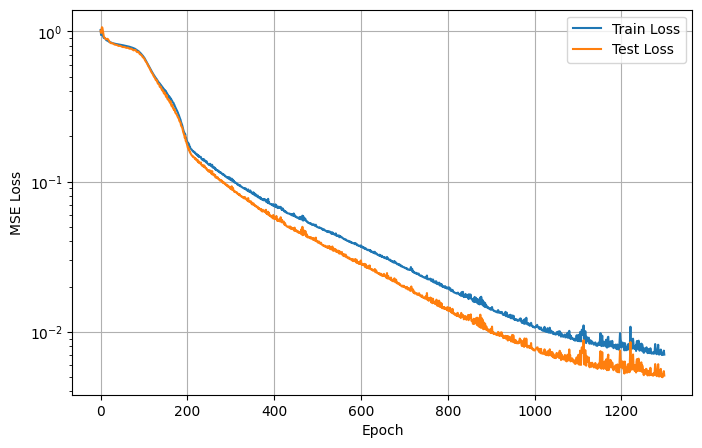

In [69]:
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid()
plt.show()

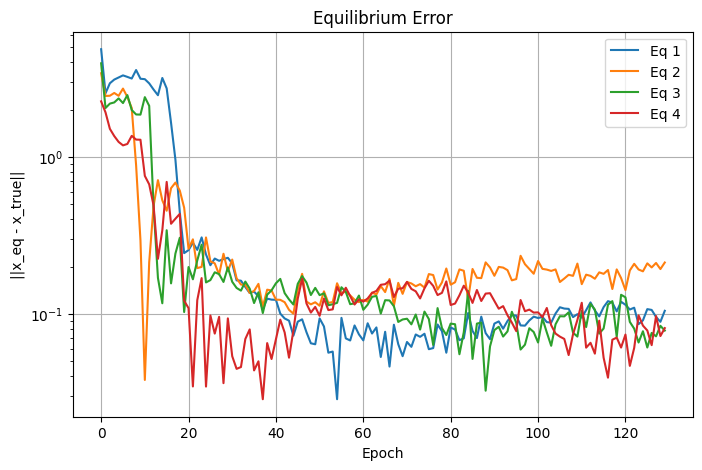

In [70]:
import numpy as np

eq_errors_history = np.array(eq_errors_history)  # shape (epochs, 4)

plt.figure(figsize=(8,5))

for i in range(eq_errors_history.shape[1]):
    plt.plot(eq_errors_history[:, i], label=f"Eq {i+1}")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("||x_eq - x_true||")
plt.title("Equilibrium Error")
plt.legend()
plt.grid()

plt.show()

In [33]:
func = node_adj.func

In [34]:
def get_predicted_equilibria(func, true_equilibria, t0=0.0, steps=300, lr=0.02, noise=0.2):
    pred_eqs = []
    residuals = []
    starts = []

    for x_true_eq in true_equilibria:
        x0 = x_true_eq + noise * torch.randn_like(x_true_eq)
        x_eq, res = find_equilibrium(func, x0, t0=t0, steps=steps, lr=lr)

        starts.append(x0.detach().cpu())
        pred_eqs.append(x_eq.detach().cpu())
        residuals.append(res)

    return torch.stack(pred_eqs), torch.tensor(residuals), torch.stack(starts)




In [35]:
pred_equilibria, residuals, starts = get_predicted_equilibria(
    node_adj.func,
    true_equilibria,
    t0=0.0,
    steps=300,
    lr=0.02,
    noise=0.2
)

torch.save({
    "true_equilibria": true_equilibria.detach().cpu(),
    "pred_equilibria": pred_equilibria,
    "residuals": residuals,
    "starts": starts
}, "equilibria_results.pt")

In [48]:
def compute_true_eigenvalues():
    gt = Cos().to(device)
    true_eigs = []

    for x_eq in true_equilibria:
        J = jacobian_2d(gt, x_eq, t0=0.0)
        eigvals = torch.linalg.eigvals(J)
        true_eigs.append(eigvals.detach().cpu())

    return true_eigs
true_eigs = compute_true_eigenvalues()

In [72]:
def plot_eigenvalues_vs_epoch_manual_true(eigvals_history, epoch_marks):
    import matplotlib.pyplot as plt

    # вручную заданные true eigenvalues
    true_eigs = [
        [3 * math.sqrt(2),  1 * math.sqrt(2)],   # Eq 1: unstable
        [math.sqrt(6),     -math.sqrt(6)],       # Eq 2: saddle
        [math.sqrt(6),     -math.sqrt(6)],       # Eq 3: saddle
        [-1 * math.sqrt(2), -3 * math.sqrt(2)]   # Eq 4: stable
    ]

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    axes = axes.flatten()

    for eq_idx in range(4):
        re1, re2 = [], []
        im1, im2 = [], []

        for snapshot in eigvals_history:
           lam = snapshot[eq_idx].numpy()
           lam_sorted = sorted(lam, key=lambda x: x.real)

           lam1 = lam_sorted[0]
           lam2 = lam_sorted[1]

           re1.append(lam1.real)
           re2.append(lam2.real)
           im1.append(lam1.imag)
           im2.append(lam2.imag)

        ax = axes[eq_idx]

        # learned eigenvalues
        ax.plot(epoch_marks, re1, label='Re(λ1)', linewidth=2)
        ax.plot(epoch_marks, re2, label='Re(λ2)', linewidth=2)
        ax.plot(epoch_marks, im1, '--', label='Im(λ1)', linewidth=2)
        ax.plot(epoch_marks, im2, '--', label='Im(λ2)', linewidth=2)

        # true eigenvalues — горизонтальные линии
        ax.axhline(true_eigs[eq_idx][0], linestyle='-', linewidth=1.5, alpha=0.7, label='true λ')
        ax.axhline(true_eigs[eq_idx][1], linestyle='-', linewidth=1.5, alpha=0.7)

        # нулевая линия
        ax.axhline(0.0, linestyle='--', linewidth=1)

        # подписи true значений справа
        ax.text(epoch_marks[-1], true_eigs[eq_idx][0], f'{true_eigs[eq_idx][0]:.3f}', fontsize=9, va='bottom')
        ax.text(epoch_marks[-1], true_eigs[eq_idx][1], f'{true_eigs[eq_idx][1]:.3f}', fontsize=9, va='bottom')

        ax.set_title(f'Equilibrium {eq_idx+1}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Eigenvalue')
        ax.grid(True)
        ax.legend()

    plt.tight_layout()
    plt.show()

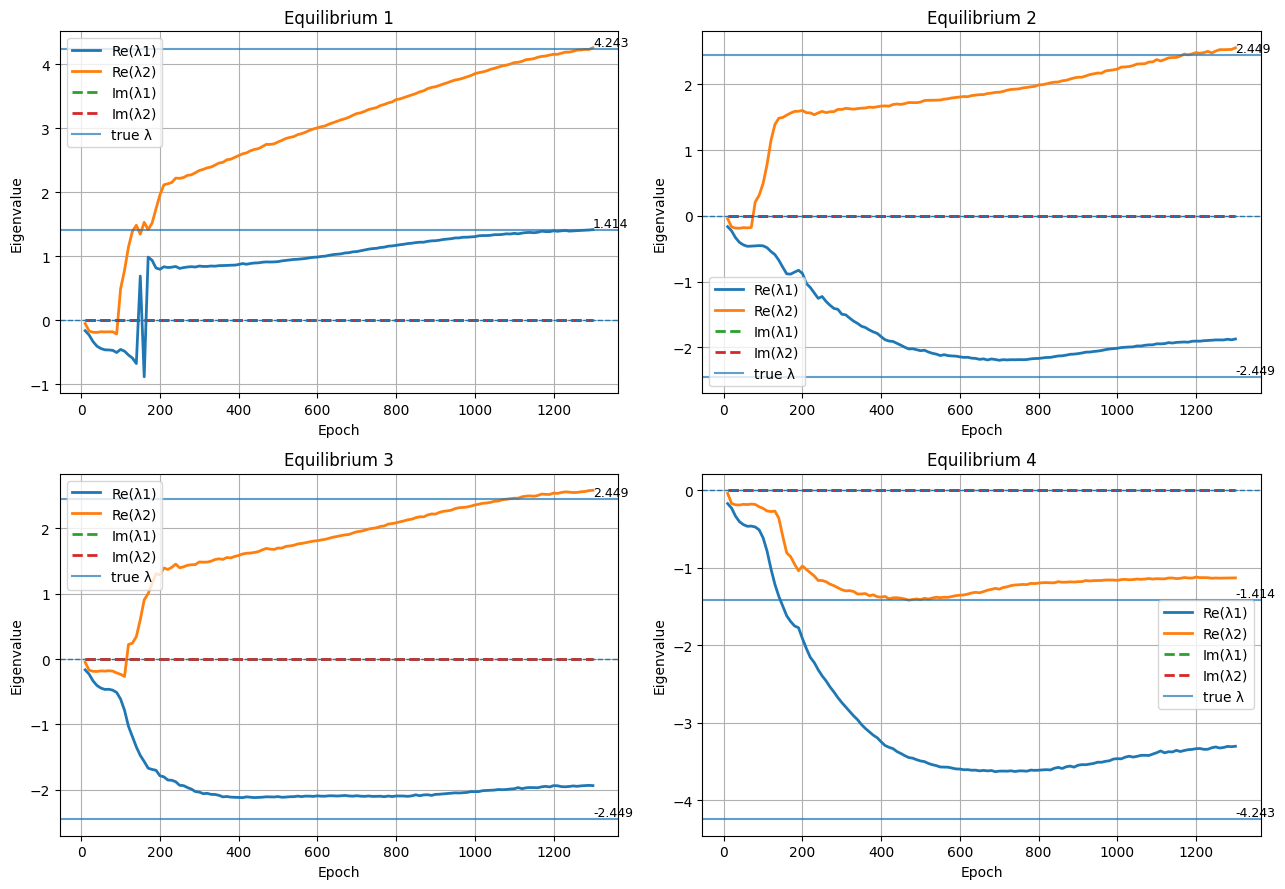

In [73]:
plot_eigenvalues_vs_epoch_manual_true(eigvals_history, epoch_marks)